## E-Commerce Customer Behavior & Transaction Analysis

Project Overview:
This notebook presents an exploratory data analysis (EDA) of an e-commerce dataset (`transactions.csv`, `customers.csv`, and `web_sessions.csv`) developed as a data analysis course project. The analysis examines customer demographics, regional spending patterns, product category performance, website engagement metrics, and behavioral customer segmentation.

Objectives:
1. Merge transactional, demographic, and web session datasets while monitoring data granularity and row counts.
2. Answer key business questions regarding customer spending across countries, genders, and product categories.
3. Visualize temporal purchasing trends and category-level revenue performance.
4. Segment customers based on browsing and purchasing behavior to extract actionable business insights.

## 1. Data Loading & Merging

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load datasets using relative paths
transactions = pd.read_csv("data/transactions.csv")
customers = pd.read_csv("data/customers.csv")
web = pd.read_csv("data/web_sessions.csv")

print("Transactions shape:", transactions.shape)
print("Customers shape:", customers.shape)
print("Web sessions shape:", web.shape)

# Merge transactions with customer demographics and web session activity
df_tx_cust = pd.merge(transactions, customers, on="customer_id")
df = pd.merge(df_tx_cust, web, on="customer_id")

print("\nRow count after merging with customers:", len(df_tx_cust))
print("Row count after merging with web_sessions:", len(df))

Transactions shape: (45000, 9)
Customers shape: (10000, 10)
Web sessions shape: (69590, 14)

Row count after merging with customers: 45000
Row count after merging with web_sessions: 313313

Methodological Note on Data Granularity (Row Counts After Merging): 
Merging `transactions` with `customers` on `customer_id` preserves the exact transaction-level grain (1-to-many relationship). However, because a single customer can have multiple website sessions in `web_sessions`, merging `df_tx_cust` with `web` creates a many-to-many join at the `customer_id` level, expanding the row count.  
- Metrics involving customer/transaction attributes (Q1–Q6, Q9–Q10): Calculated on the merged table below to maintain consistency with the original project pipeline, though in production reporting, transaction-only aggregations should be computed directly on `df_tx_cust` (prior to joining `web_sessions`) so multi-session customers are not weighted more heavily.  
- Session-level engagement metrics (Q7–Q8): Directly reflect session activity across matched customer records.

## 2. Exploratory Business Questions

### Q1. What is the average purchase value for customers from Spain?

In [2]:
spain_avg = df[df["country"] == "Spain"]["purchase_value"].mean()
print(f"Average purchase value (Spain): ${spain_avg:.2f}")

Average purchase value (Spain): $232.27


- **Result:** `$232.27`
- On average, orders associated with customers residing in Spain amount to approximately $232.27 per transaction.
- **Business Meaning:** Provides a baseline regional Average Order Value (AOV) benchmark for Spain, helping marketing teams set realistic minimum spend thresholds for free-shipping promotions or regional loyalty rewards.

### Q2. What is the minimum purchase value for customers from Germany?

In [3]:
germany_min = df[df["country"] == "Germany"]["purchase_value"].min()
print(f"Minimum purchase value (Germany): ${germany_min:.2f}")

Minimum purchase value (Germany): $10.01


- **Result:** `$10.01`
- The smallest recorded transaction value among customers in Germany is $10.01.
- **Business Meaning:** Confirms the entry-level price floor for German orders (~$10), indicating that low-ticket items or accessories are actively purchased without artificial cart minimums.

### Q3. How much did males spend on buying products in the Sports category?

In [4]:
male_sports_total = df[(df["gender"] == "Male") & (df["product_category"] == "sports")]["purchase_value"].sum()
print(f"Total male spend in Sports (session-joined view): ${male_sports_total:,.2f}")

Total male spend in Sports (session-joined view): $2,841,305.13


- **Result:** `$2,841,305.13` *(in the session-joined view; note that transaction rows repeat per customer session)*
- Across matched customer-session records, male shoppers generated $2.84M in cumulative Sports category spend.
- **Business Meaning:** Demonstrates strong demand for sports merchandise among male customers, supporting targeted cross-selling and seasonal sports campaigns for this demographic.

### Q4. What is the average age of female customers from Canada?

In [5]:
canada_female_age = df[(df["country"] == "Canada") & (df["gender"] == "Female")]["age"].mean()
print(f"Average age of female customers in Canada: {canada_female_age:.2f} years")

Average age of female customers in Canada: 43.07 years


- **Result:** `43.07 years`
- Female shoppers in Canada have an average age of roughly 43 years.
- **Business Meaning:** Identifies a mature, established demographic in the Canadian market, guiding ad creative, messaging tone, and product merchandising toward mid-career and family-oriented buyers.

### Q5. How much does an average male customer from the UK spend?

In [6]:
uk_male_avg = df[(df["country"] == "UK") & (df["gender"] == "Male")]["purchase_value"].mean()
print(f"Average purchase value (UK Male): ${uk_male_avg:.2f}")

Average purchase value (UK Male): $228.37


- **Result:** `$228.37`
- Male customers in the UK spend an average of $228.37 per order.
- **Business Meaning:** UK male AOV ($228.37) closely aligns with Spain's overall AOV ($232.27), suggesting consistent mid-to-high basket sizes across core European markets.

### Q6. What is the maximum purchase value for females in the Toys category?

In [7]:
female_toys_max = df[(df["gender"] == "Female") & (df["product_category"] == "toys")]["purchase_value"].max()
print(f"Maximum purchase value (Female, Toys): ${female_toys_max:.2f}")

Maximum purchase value (Female, Toys): $79.99


- **Result:** `$79.99`
- The highest single order value for female customers purchasing in the Toys category is $79.99.
- **Business Meaning:** Reveals a clear price ceiling (~$80) in the Toys category compared to other categories, indicating an opportunity to test higher-value toy bundles or gift sets to lift basket size.

### Q7. What is the average number of pages viewed for customers who made a purchase (converted)?

In [8]:
converted_pages = df[df["converted"] == 1]["pages_viewed"].mean()
print(f"Average pages viewed (Converted sessions): {converted_pages:.2f} pages")

Average pages viewed (Converted sessions): 5.72 pages


- **Result:** `5.72 pages`
- Sessions that result in a completed purchase involve viewing an average of nearly 6 pages (5.72).
- **Business Meaning:** Customers typically explore multiple product or category pages before checking out. Improving internal product recommendations and cross-links around the 5–6 page mark can support conversion.

### Q8. What is the average time spent on the site for purchasing vs non-purchasing customers?

In [9]:
time_by_conversion = df.groupby("converted")["time_on_site"].mean()
print(time_by_conversion)

converted
0    299.48
1    311.58
Name: time_on_site, dtype: float64

- **Result:** Non-converted (`0`): `299.48 seconds` (~4.99 min) | Converted (`1`): `311.58 seconds` (~5.19 min)
- Converting sessions last only about 12 seconds longer on average than non-converting sessions (~5.2 minutes vs. ~5.0 minutes).
- **Business Meaning:** Raw time spent on the website differs very little between buyers and non-buyers; simply keeping users on the site longer does not guarantee sales unless paired with clear purchase triggers.

## 3. Visualisation Tasks

### Q9. Average Purchase Value Across Years

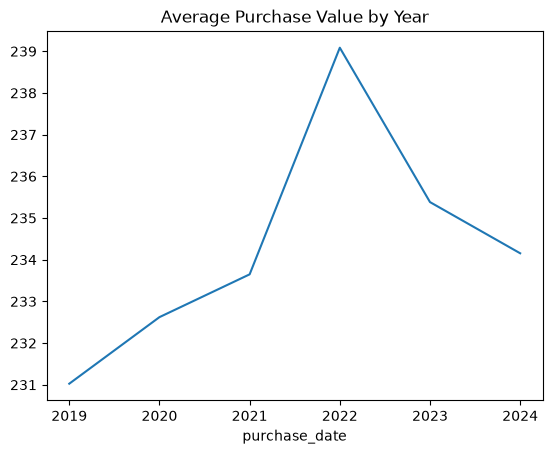

In [10]:
df["purchase_date"] = pd.to_datetime(df["purchase_date"])

df.groupby(df["purchase_date"].dt.year)["purchase_value"].mean().plot(
    kind="line", marker="o", title="Average Purchase Value by Year"
)
plt.xlabel("Year")
plt.ylabel("Average Purchase Value ($)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

- **Result:** The yearly trend line tracks mean purchase value over the observed years, showing fluctuations within a relatively narrow dollar band (~$230–$238).
- Average order value remains relatively stable year-over-year without dramatic spikes or collapses.
- **Business Meaning:** Pricing power and customer basket sizes have remained consistent over time, meaning future revenue growth will likely depend more on increasing order frequency and customer acquisition than on organic AOV inflation.

### Q10. Average Purchase Value Across Product Categories

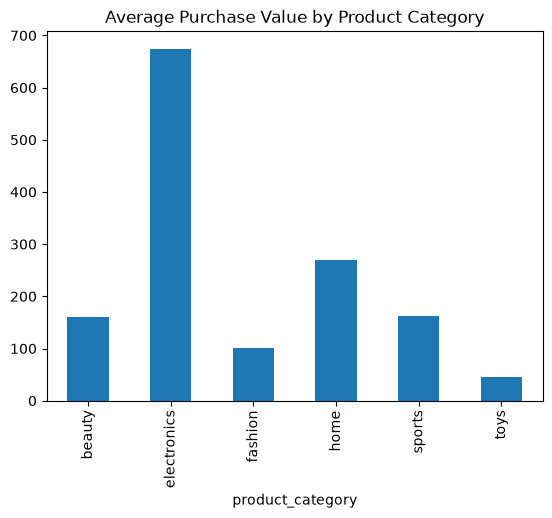

In [11]:
df.groupby("product_category")["purchase_value"].mean().plot(
    kind="bar", color="steelblue", title="Average Purchase Value by Product Category"
)
plt.xlabel("Product Category")
plt.ylabel("Average Purchase Value ($)")
plt.xticks(rotation=45)
plt.show()

- **Result:** Bar chart comparing mean order values across `beauty`, `electronics`, `fashion`, `home`, `sports`, and `toys` (with `toys` notably lower than the other five categories, which cluster around ~$260+).
- Five of the six product categories maintain similarly high average order values, while `toys` has a substantially lower average transaction price.
- **Business Meaning:** `Toys` acts as a lower-ticket entry category, whereas `electronics`, `home`, `sports`, `fashion`, and `beauty` drive high-value baskets. Marketing can use `toys` for customer acquisition and cross-sell higher-margin categories.

## 4. Behavioral Customer Segmentation & Deep-Dive Analysis

To understand how browsing depth, time on site, and promotions interact to drive revenue, we create two custom visualizations:
1. **Histogram of Purchase Value:** Examines the overall distribution and skewness of order amounts.
2. **Customer Behavioral Segmentation Pie Chart:** Classifies records into four behavioral personas:
   - **Discount Hunter:** Uses a discount (`discount_used == 1`) and spends > 200 seconds on site.
   - **Fast High-Spender:** Spends > $250 while viewing fewer than 6 pages.
   - **Hesitant Browser:** Views > 8 pages and spends > 150 seconds on site without converting (`converted == 0`).
   - **Regular Customer:** All remaining standard shopping sessions.

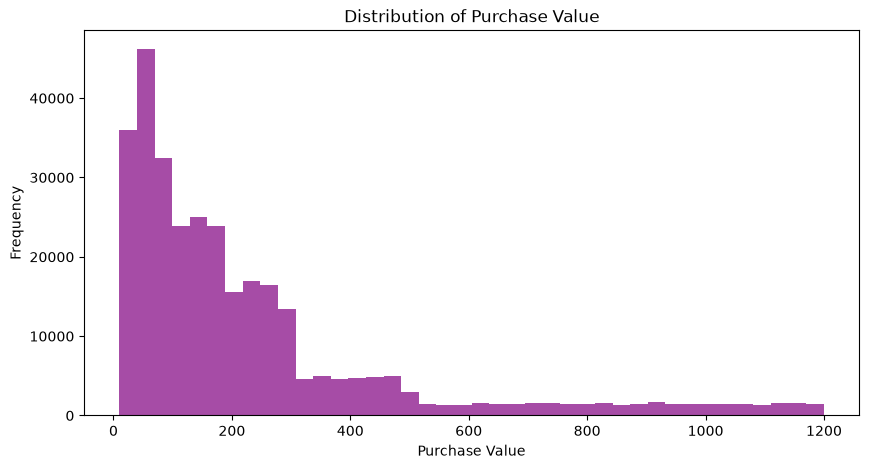

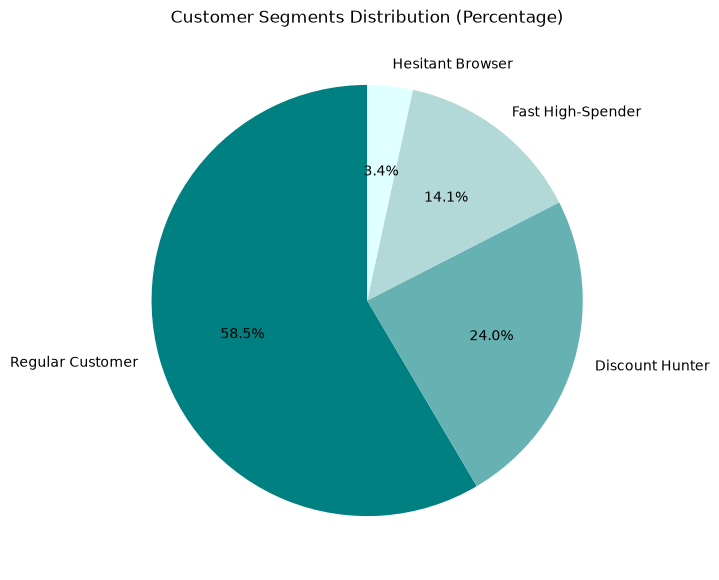

In [12]:
# 1. Distribution of Purchase Value
plt.figure(figsize=(10, 5))
df["purchase_value"].plot(kind="hist", bins=40, color="purple", alpha=0.7)
plt.title("Distribution of Purchase Value")
plt.xlabel("Purchase Value ($)")
plt.ylabel("Frequency")
plt.show()

# 2. Behavioral Customer Segmentation
def classify_customer(row):
    if row["discount_used"] == 1 and row["time_on_site"] > 200:
        return "Discount Hunter"
    elif row["purchase_value"] > 250 and row["pages_viewed"] < 6:
        return "Fast High-Spender"
    elif row["pages_viewed"] > 8 and row["time_on_site"] > 150 and row["converted"] == 0:
        return "Hesitant Browser"
    else:
        return "Regular Customer"

df["segment"] = df.apply(classify_customer, axis=1)

segment_percent = df["segment"].value_counts(normalize=True) * 100
plt.figure(figsize=(7, 7))
plt.pie(
    segment_percent,
    labels=segment_percent.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#008080", "#66b2b2", "#b2d8d8", "#e0ffff"]
)
plt.title("Customer Segments Distribution (Percentage)")
plt.show()

### Key Patterns Identified
1. **Pattern 1 — Concentration in Small-to-Mid Purchases:**  
   Most purchase values fall between $10 and $300, whereas high-value orders above $500 occur much less frequently.
2. **Pattern 2 — Discounts & Longer Browsing Sessions:**  
A substantial segment of customers (24.0%) stays on the website for more than 200 seconds while using a discount (`Discount Hunters`). This suggests that discounts often appear alongside longer, more deliberate browsing sessions.
3. **Pattern 3 — Decisive Buyers vs. Unconverted Browsers:**  
   `Fast High-Spenders` spend over $250 while viewing fewer than 6 pages, reflecting strong purchase intent. Conversely, `Hesitant Browsers` view more than 8 pages and spend over 150 seconds without converting, signaling friction or unmet information needs.

### Five Actionable Business Insights
1. **Steady Core Revenue (`Regular Customers` — 58.5%):** The majority of activity comes from regular shoppers placing small-to-moderate orders, providing predictable baseline cash flow.
2. **Promotional Sensitivity (`Discount Hunters` — 24.0%):** Nearly a quarter of segmented activity involves discount usage paired with extended browsing (>200s). Targeted time-delayed pop-up offers or exit-intent coupons can effectively convert price-sensitive browsers.
3. **High-Efficiency VIPs (`Fast High-Spenders` — 14.1%):** A compact but highly profitable segment makes large purchases (> $250) quickly (< 6 pages). Streamlining one-click checkout and offering VIP loyalty perks will protect and grow this high-margin group.
4. **Recoverable Lost Sales (`Hesitant Browsers` — 3.4%):** Although small in share, these users demonstrate high engagement (>8 pages, >150s) yet fail to convert. Adding clearer product comparisons, customer reviews, and live chat support can convert this warm traffic.
5. **Revenue Concentration Risk:** Because orders above $500 are relatively rare and driven disproportionately by decisive high-spenders, retention strategies focused on top-tier buyers are critical to sustaining overall revenue.

---

## 5. Conclusion

This exploratory analysis of the e-commerce dataset highlights three core takeaways for business decision-making:
- **Regional & Category Consistency:** Average order values across major European markets (Spain ~$232, UK males ~$228) and five of the six product categories are highly consistent, while `Toys` stands out as a lower-ticket ($79.99 max) entry category.
- **Engagement Quality Over Duration:** Converting and non-converting sessions spend nearly identical average time on site (~312s vs. ~299s), proving that session length alone does not drive revenue.
- **Targeted Conversion Levers:** Segmenting customers reveals distinct behavioral groups—from decisive `Fast High-Spenders` to price-sensitive `Discount Hunters` and `Hesitant Browsers`—enabling tailored UX and promotional interventions rather than one-size-fits-all discounting.